In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer

In [19]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

In [20]:
print(X.shape)             # (569, 30)
print(data.target_names)   # ['malignant' 'benign']
print(y.value_counts())    # répartition des deux classes
X.head()                   # aperçu des premières lignes

(569, 30)
['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(426, 30) (143, 30)


In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
)
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000,
                               random_state=42))])

In [23]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=data.target_names))
print("AUC :", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        53
      benign       0.99      0.96      0.97        90

    accuracy                           0.97       143
   macro avg       0.96      0.97      0.96       143
weighted avg       0.97      0.97      0.97       143

AUC : 0.9951781970649896


In [24]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score

# Les "étiquettes" de l'arbre sont les prédictions du réseau
nn_train = model.predict(X_train)
nn_test = model.predict(X_test)

surrogate = DecisionTreeClassifier(max_depth=3, random_state=42)
surrogate.fit(X_train, nn_train)

fidelity = accuracy_score(nn_test, surrogate.predict(X_test))
print("Fidélité (arbre vs réseau) :", round(fidelity, 3))
print("Précision de l'arbre vs vraies étiquettes :",
      round(accuracy_score(y_test, surrogate.predict(X_test)), 3))

Fidélité (arbre vs réseau) : 0.937
Précision de l'arbre vs vraies étiquettes : 0.944


In [25]:
print(export_text(surrogate, feature_names=list(X.columns)))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



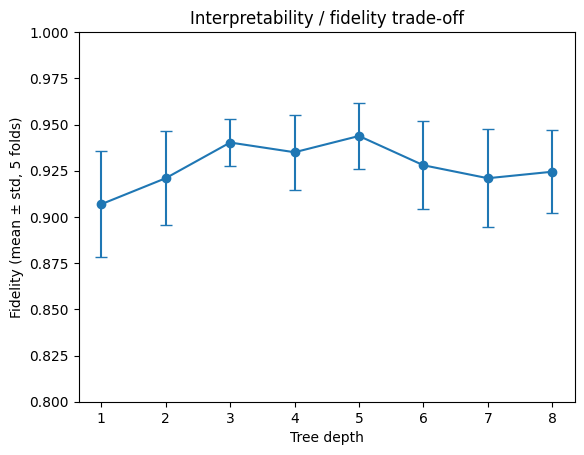

In [26]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {d: [] for d in range(1, 9)}

for tr, te in skf.split(X, y):
    m = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42))
    m.fit(X.iloc[tr], y.iloc[tr])
    p_tr, p_te = m.predict(X.iloc[tr]), m.predict(X.iloc[te])
    for d in results:
        t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X.iloc[tr], p_tr)
        results[d].append(accuracy_score(p_te, t.predict(X.iloc[te])))

depths = list(results)
means = [np.mean(results[d]) for d in depths]
stds = [np.std(results[d]) for d in depths]

plt.errorbar(depths, means, yerr=stds, marker="o", capsize=4)
plt.ylim(0.8, 1.0)
plt.xlabel("Tree depth")
plt.ylabel("Fidelity (mean ± std, 5 folds)")
plt.title("Interpretability / fidelity trade-off")
plt.savefig("fidelity_vs_depth.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
print("Profondeur 3 :", round(means[2], 3), "±", round(stds[2], 3))

Profondeur 3 : 0.94 ± 0.013


In [28]:
print(export_text(surrogate, feature_names=list(X.columns), show_weights=True))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- weights: [1.00, 250.00] class: 1
|   |   |--- area error >  91.56
|   |   |   |--- weights: [1.00, 0.00] class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- weights: [3.00, 9.00] class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- weights: [18.00, 2.00] class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- weights: [0.00, 5.00] class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- weights: [2.00, 3.00] class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- weights: [132.00, 0.00] class: 0



In [29]:
!pip install clingo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 6.8 MB/s  0:00:00


In [30]:
import numpy as np
import clingo
from sklearn.tree import _tree

tree = surrogate.tree_
names = list(X.columns)
SCALE = 1000
atom = lambda n: n.replace(" ", "_")

rules = []
def recurse(node, conds):
    if tree.feature[node] != _tree.TREE_UNDEFINED:
        f = atom(names[tree.feature[node]])
        t = int(tree.threshold[node] * SCALE)
        k = len(conds)
        recurse(tree.children_left[node],
                conds + [f"val(P,{f},V{k}), V{k} <= {t}"])
        recurse(tree.children_right[node],
                conds + [f"val(P,{f},V{k}), V{k} > {t}"])
    else:
        cls = int(tree.value[node][0].argmax())
        head = "benign(P)" if cls == 1 else "malignant(P)"
        rules.append(f"{head} :- patient(P), " + ", ".join(conds) + ".")

recurse(0, [])
print("\n".join(rules))

benign(P) :- patient(P), val(P,worst_radius,V0), V0 <= 16795, val(P,worst_concave_points,V1), V1 <= 135, val(P,area_error,V2), V2 <= 91555.
malignant(P) :- patient(P), val(P,worst_radius,V0), V0 <= 16795, val(P,worst_concave_points,V1), V1 <= 135, val(P,area_error,V2), V2 > 91555.
benign(P) :- patient(P), val(P,worst_radius,V0), V0 <= 16795, val(P,worst_concave_points,V1), V1 > 135, val(P,worst_texture,V2), V2 <= 25619.
malignant(P) :- patient(P), val(P,worst_radius,V0), V0 <= 16795, val(P,worst_concave_points,V1), V1 > 135, val(P,worst_texture,V2), V2 > 25619.
benign(P) :- patient(P), val(P,worst_radius,V0), V0 > 16795, val(P,texture_error,V1), V1 <= 473.
benign(P) :- patient(P), val(P,worst_radius,V0), V0 > 16795, val(P,texture_error,V1), V1 > 473, val(P,worst_concavity,V2), V2 <= 190.
malignant(P) :- patient(P), val(P,worst_radius,V0), V0 > 16795, val(P,texture_error,V1), V1 > 473, val(P,worst_concavity,V2), V2 > 190.


In [31]:
facts = []
for i, (_, row) in enumerate(X_test.iterrows()):
    facts.append(f"patient({i}).")
    for name, v in row.items():
        facts.append(f"val({i},{atom(name)},{int(v * SCALE)}).")

ctl = clingo.Control(["--warn=none"])
ctl.add("base", [], "\n".join(rules) + "\n" + "\n".join(facts))
ctl.ground([("base", [])])

benign = set()
def on_model(m):
    for a in m.symbols(atoms=True):
        if a.name == "benign":
            benign.add(a.arguments[0].number)

ctl.solve(on_model=on_model)

asp_pred = np.array([1 if i in benign else 0 for i in range(len(X_test))])
print("Accord ASP vs arbre :", (asp_pred == surrogate.predict(X_test)).mean())
print("Fidélité ASP vs réseau :", (asp_pred == nn_test).mean())

Accord ASP vs arbre : 1.0
Fidélité ASP vs réseau : 0.9370629370629371


In [32]:
open("rules.lp", "w").write("\n".join(rules))

from google.colab import files
files.download("rules.lp")
files.download("fidelity_vs_depth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
print("Profondeur 3 :", round(means[2], 3), "±", round(stds[2], 3))

Profondeur 3 : 0.94 ± 0.013


In [34]:
open("rules.lp", "w").write("\n".join(rules))

from google.colab import files
files.download("rules.lp")
files.download("fidelity_vs_depth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>